# 02 — Pakokku rice-price series and missingness investigation

## Objective

Notebook 01 selected **Rice (low quality), Retail, MMK/KG** and **Pakokku Myo Ma Market (Market ID: 1664)**. This notebook investigates missing months in that one market.

Other markets are used only as supporting context. They do not replace Pakokku as the main forecasting series.

**Scope:** identify gaps, describe their length, inspect prices around each gap, and compare the same months with other markets. This is a descriptive investigation; it cannot prove that missingness is MCAR, MAR, or MNAR.

In [3]:
# 1. Environment and configuration

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/prices.csv")

TARGET_COMMODITY = "Rice (low quality)"
TARGET_UNIT = "KG"
TARGET_PRICE_TYPE = "Retail"
TARGET_CURRENCY = "MMK"
PAKOKKU_ID = 1664

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Check the notebook working directory and DATA_PATH."
    )

## 2. Recreate the monthly rice dataset

This notebook repeats the minimum preparation needed to run independently. The filters and aggregation are kept identical to Notebook 01.

In [4]:
df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = {
    "date", "commodity", "market_id", "market",
    "unit", "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

rice_df = df[
    (df["commodity"] == TARGET_COMMODITY)
    & (df["unit"] == TARGET_UNIT)
    & (df["pricetype"] == TARGET_PRICE_TYPE)
    & (df["currency"] == TARGET_CURRENCY)
].dropna(subset=["date", "price"]).copy()

rice_df["month"] = rice_df["date"].dt.to_period("M")

monthly_rice = (
    rice_df.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observation_count=("price", "count")
    )
    .reset_index()
    .sort_values(["market_id", "month"])
)

print("Monthly market-price rows:", len(monthly_rice))
print("Markets:", monthly_rice["market_id"].nunique())

Monthly market-price rows: 10231
Markets: 298


## 3. Extract Pakokku's monthly price series

Work with Pakokku only for the primary analysis. Do not calculate Pakokku's missing months using another market's date range.

In [5]:
pakokku = (
    monthly_rice[monthly_rice["market_id"] == PAKOKKU_ID]
    .sort_values("month")
    .copy()
)

if pakokku.empty:
    raise ValueError(f"No rice observations found for market ID {PAKOKKU_ID}.")

print("Market:", pakokku["market"].iloc[0])
print("Observed market-months:", pakokku["month"].nunique())
print("First observed month:", pakokku["month"].min())
print("Last observed month:", pakokku["month"].max())
display(pakokku.head())

Market: Pakokku Myo Ma Market
Observed market-months: 146
First observed month: 2014-01
Last observed month: 2026-09


,market_id,market,month,monthly_price,observation_count
4360,1664,Pakokku Myo Ma Market,2014-01,693.0,1
4361,1664,Pakokku Myo Ma Market,2014-02,693.0,1
4362,1664,Pakokku Myo Ma Market,2014-03,693.0,1
4363,1664,Pakokku Myo Ma Market,2014-04,712.0,1
4364,1664,Pakokku Myo Ma Market,2014-05,708.0,1


## 4. Create Pakokku's complete monthly timeline

Reindex only from Pakokku's first observed month to its last observed month. Missing rows created by `reindex` represent internal months with no recorded monthly price. Months before the first observation and after the last observation are outside this investigation window.

In [6]:
pakokku_months = pd.period_range(
    start=pakokku["month"].min(),
    end=pakokku["month"].max(),
    freq="M"
)

pakokku_ts = (
    pakokku.set_index("month")
    .reindex(pakokku_months)
)
pakokku_ts.index.name = "month"

observed_months = pakokku_ts["monthly_price"].notna().sum()
missing_months = pakokku_ts["monthly_price"].isna().sum()
span_months = len(pakokku_ts)

pakokku_summary = pd.DataFrame({
    "first_month": [pakokku_ts.index.min()],
    "last_month": [pakokku_ts.index.max()],
    "span_months": [span_months],
    "observed_months": [observed_months],
    "missing_months": [missing_months],
    "missing_percentage": [round(missing_months / span_months * 100, 2)]
})
display(pakokku_summary)

,first_month,last_month,span_months,observed_months,missing_months,missing_percentage
0,2014-01,2026-09,153,146,7,4.58


## 5. Plot the original monthly price series

The line should break where a month has no observed price. Do not connect across a missing interval or replace missing values for this plot.

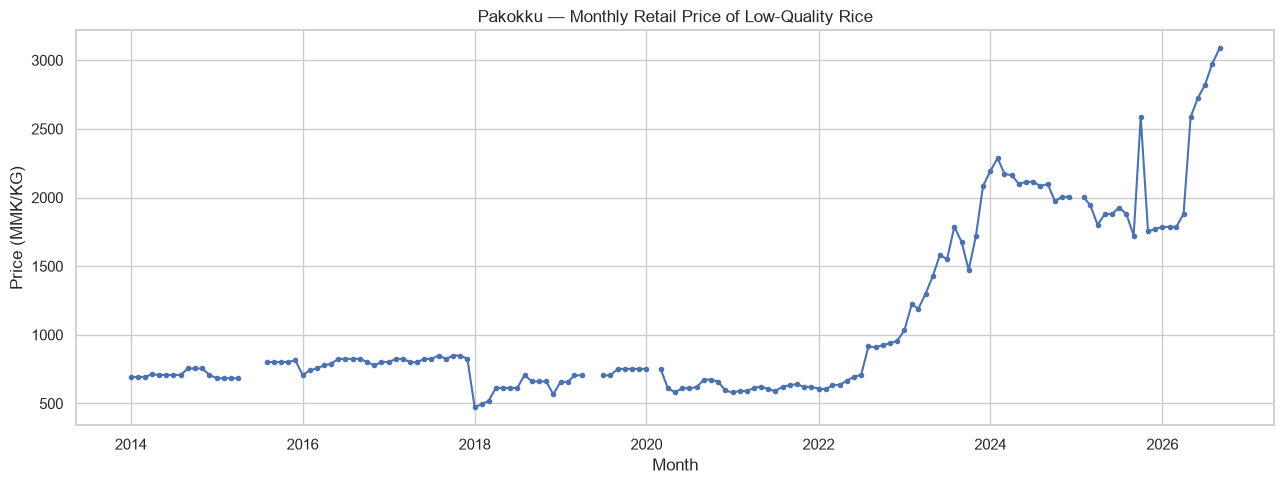

In [7]:
plt.figure(figsize=(13, 5))
plt.plot(
    pakokku_ts.index.to_timestamp(),
    pakokku_ts["monthly_price"],
    marker="o",
    markersize=3,
    linewidth=1.5
)
plt.title("Pakokku — Monthly Retail Price of Low-Quality Rice")
plt.xlabel("Month")
plt.ylabel("Price (MMK/KG)")
plt.tight_layout()
plt.show()

## 6. Identify consecutive missing periods

Group adjacent missing months into individual gaps. This produces one row per gap.

In [8]:
is_missing = pakokku_ts["monthly_price"].isna()
missing_positions = np.flatnonzero(is_missing.to_numpy())

gap_positions = np.split(
    missing_positions,
    np.where(np.diff(missing_positions) > 1)[0] + 1
)

gap_rows = []
for positions in gap_positions:
    if len(positions) == 0:
        continue
    gap_rows.append({
        "gap_start": pakokku_ts.index[positions[0]],
        "gap_end": pakokku_ts.index[positions[-1]],
        "missing_months": len(positions)
    })

gap_summary = pd.DataFrame(gap_rows)
display(gap_summary)

,gap_start,gap_end,missing_months
0,2015-05,2015-07,3
1,2019-05,2019-06,2
2,2020-02,2020-02,1
3,2025-01,2025-01,1


## 7. Inspect observed prices around each gap

A short gap bounded by observed prices may be easier to review than a long gap, but the neighboring prices do not prove what happened during the missing months. This table is diagnostic only; it does not recommend automatic interpolation.

In [9]:
price_series = pakokku_ts["monthly_price"]
gap_context_rows = []

for _, gap in gap_summary.iterrows():
    start_pos = pakokku_ts.index.get_loc(gap["gap_start"])
    end_pos = pakokku_ts.index.get_loc(gap["gap_end"])

    previous_price = price_series.iloc[start_pos - 1] if start_pos > 0 else np.nan
    next_price = price_series.iloc[end_pos + 1] if end_pos < len(price_series) - 1 else np.nan

    if pd.notna(previous_price) and pd.notna(next_price) and previous_price != 0:
        change_pct = (next_price / previous_price - 1) * 100
    else:
        change_pct = np.nan

    gap_context_rows.append({
        "gap_start": gap["gap_start"],
        "gap_end": gap["gap_end"],
        "missing_months": int(gap["missing_months"]),
        "previous_observed_price": previous_price,
        "next_observed_price": next_price,
        "change_between_boundary_prices_pct": round(change_pct, 2)
            if pd.notna(change_pct) else np.nan
    })

gap_context = pd.DataFrame(gap_context_rows)
display(gap_context)

,gap_start,gap_end,missing_months,previous_observed_price,next_observed_price,change_between_boundary_prices_pct
0,2015-05,2015-07,3,684.00,802.00,17.25
1,2019-05,2019-06,2,704.89,704.89,0.00
2,2020-02,2020-02,1,751.88,751.88,0.00
3,2025-01,2025-01,1,2005.00,2001.90,-0.15


## 8. Visualize Pakokku's missing months by year

This heatmap shows only Pakokku's own internal timeline. A red cell indicates a month with no recorded monthly price.

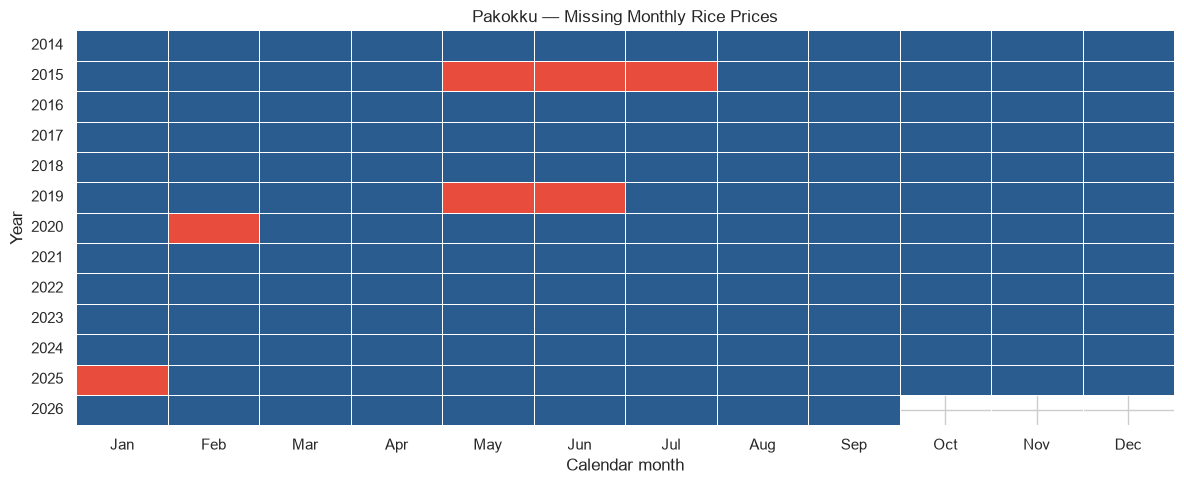

In [10]:
missing_by_year = (
    pakokku_ts
    .assign(
        year=lambda frame: frame.index.year,
        calendar_month=lambda frame: frame.index.month,
        is_missing=lambda frame: frame["monthly_price"].isna().astype(int)
    )
    .pivot(index="year", columns="calendar_month", values="is_missing")
    .reindex(columns=range(1, 13))
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]
missing_by_year.columns = month_labels

plt.figure(figsize=(12, 5))
sns.heatmap(
    missing_by_year,
    cmap=["#2b5c8f", "#e74c3c"],
    vmin=0, vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar=False
)
plt.title("Pakokku — Missing Monthly Rice Prices")
plt.xlabel("Calendar month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

## 9. Build a market-month matrix for supporting context

Now compare Pakokku's gaps with other markets. First create a complete time index across the rice dataset. Each market is considered **active** from its first observed month through its last observed month.

This is an operational approximation based on the data, not verified information about each market's actual reporting schedule.

In [11]:
all_months = pd.period_range(
    start=monthly_rice["month"].min(),
    end=monthly_rice["month"].max(),
    freq="M"
)

price_matrix = (
    monthly_rice.pivot(
        index="month",
        columns="market_id",
        values="monthly_price"
    )
    .reindex(all_months)
)
price_matrix.index.name = "month"

# Determine each market's first and last observed months.
first_observed = price_matrix.apply(lambda column: column.first_valid_index())
last_observed = price_matrix.apply(lambda column: column.last_valid_index())

active_mask = pd.DataFrame(
    False, index=price_matrix.index, columns=price_matrix.columns
)

for market_id in price_matrix.columns:
    first_month = first_observed[market_id]
    last_month = last_observed[market_id]
    active_mask[market_id] = (
        (price_matrix.index >= first_month)
        & (price_matrix.index <= last_month)
    )

# Internal missing values are missing cells inside the active span.
internal_missing = price_matrix.isna() & active_mask

print("Markets in matrix:", price_matrix.shape[1])
print("Months in matrix:", price_matrix.shape[0])

Markets in matrix: 298
Months in matrix: 225


## 10. Check missingness across active markets by year and calendar month

These are pooled descriptive rates across all active market-month cells. They provide context about the wider dataset; they are not Pakokku-specific missingness rates.

In [12]:
active_by_year = active_mask.groupby(active_mask.index.year).sum()
missing_by_year = internal_missing.groupby(internal_missing.index.year).sum()

year_summary = pd.DataFrame({
    "active_market_months": active_by_year.sum(axis=1),
    "missing_market_months": missing_by_year.sum(axis=1)
})
year_summary["missing_percentage"] = (
    year_summary["missing_market_months"]
    / year_summary["active_market_months"] * 100
).round(2)
year_summary.index.name = "year"

active_by_calendar_month = active_mask.groupby(active_mask.index.month).sum()
missing_by_calendar_month = internal_missing.groupby(
    internal_missing.index.month
).sum()

calendar_month_summary = pd.DataFrame({
    "active_market_months": active_by_calendar_month.sum(axis=1),
    "missing_market_months": missing_by_calendar_month.sum(axis=1)
})
calendar_month_summary["missing_percentage"] = (
    calendar_month_summary["missing_market_months"]
    / calendar_month_summary["active_market_months"] * 100
).round(2)
calendar_month_summary.index.name = "calendar_month"

display(year_summary.sort_values("missing_percentage", ascending=False))
display(calendar_month_summary)

,active_market_months,missing_market_months,missing_percentage
year,,,
2019,492,366,74.39
2018,498,342,68.67
2013,450,224,49.78
2017,537,260,48.42
2025,1409,673,47.76
2016,590,254,43.05
2012,638,264,41.38
2015,612,231,37.75
2024,1748,656,37.53


,active_market_months,missing_market_months,missing_percentage
calendar_month,,,
1,1351,568,42.04
2,1335,428,32.06
3,1317,491,37.28
4,1349,496,36.77
5,1359,514,37.82
6,1370,515,37.59
7,1386,502,36.22
8,1388,503,36.24
9,1386,488,35.21


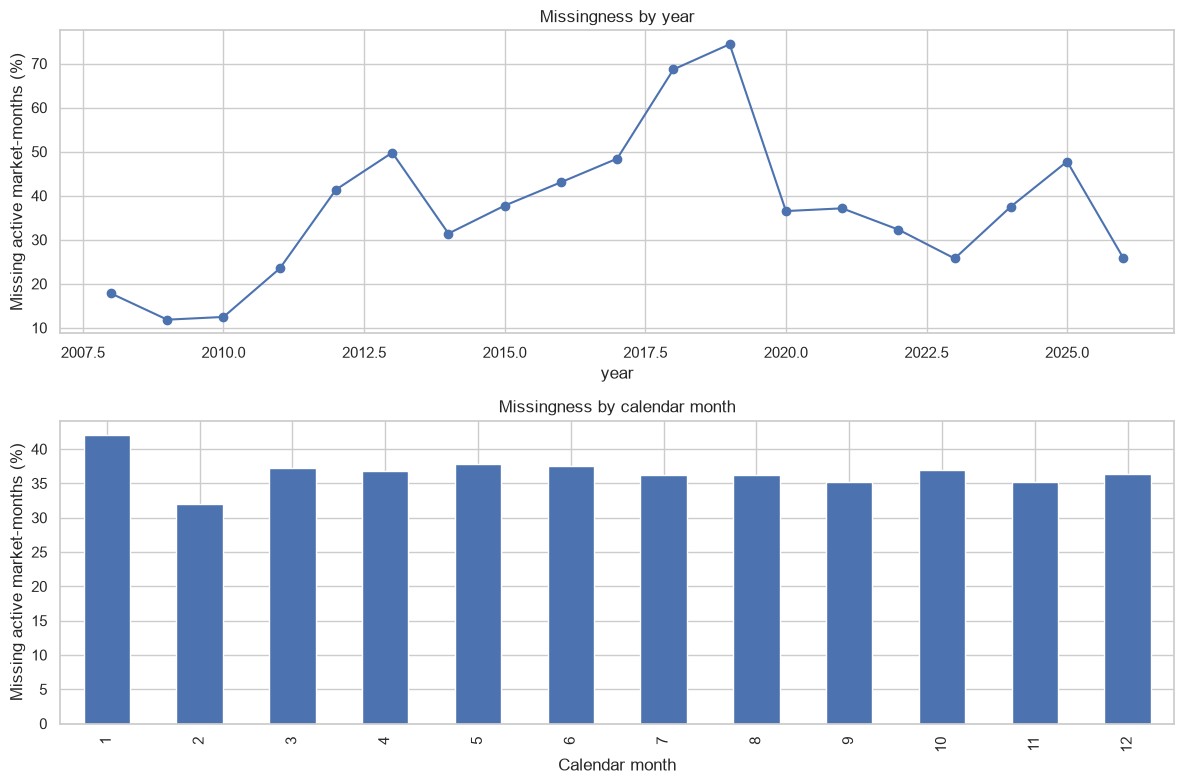

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

year_summary["missing_percentage"].plot(
    ax=axes[0], marker="o", title="Missingness by year"
)
calendar_month_summary["missing_percentage"].plot(
    ax=axes[1], kind="bar", title="Missingness by calendar month"
)

axes[0].set_ylabel("Missing active market-months (%)")
axes[1].set_ylabel("Missing active market-months (%)")
axes[1].set_xlabel("Calendar month")
plt.tight_layout()
plt.show()

## 11. Identify months with widespread missingness

Count the number of active markets missing a price in each month. The percentage uses only markets inside their observed first-to-last-month span.

In [14]:
simultaneous = pd.DataFrame(index=price_matrix.index)
simultaneous["active_markets"] = active_mask.sum(axis=1)
simultaneous["missing_markets"] = internal_missing.sum(axis=1)
simultaneous["missing_percentage"] = (
    simultaneous["missing_markets"]
    .div(simultaneous["active_markets"].replace(0, np.nan))
    .mul(100)
)

display(
    simultaneous.sort_values(
        "missing_percentage", ascending=False
    ).head(15)
)

print(
    "Months with at least 25% of active markets missing:",
    int((simultaneous["missing_percentage"] >= 25).sum())
)
print(
    "Months with at least 50% of active markets missing:",
    int((simultaneous["missing_percentage"] >= 50).sum())
)

,active_markets,missing_markets,missing_percentage
month,,,
2013-06,36,36,100.000000
2025-01,147,147,100.000000
2019-05,41,41,100.000000
2012-09,53,50,94.339623
2012-08,53,48,90.566038
2018-08,41,32,78.048780
2018-10,41,32,78.048780
2018-07,41,32,78.048780
2019-06,41,32,78.048780


Months with at least 25% of active markets missing: 172
Months with at least 50% of active markets missing: 46


## 12. Compare peer-market missingness during Pakokku's gaps

For each Pakokku missing month, calculate the percentage of **other active markets** that are also missing. Pakokku itself is excluded from the peer counts.

In [15]:
if PAKOKKU_ID not in internal_missing.columns:
    raise ValueError(f"Pakokku market ID {PAKOKKU_ID} is missing from the market matrix.")

pakokku_missing_months = internal_missing.index[
    internal_missing[PAKOKKU_ID]
]

peer_active_count = active_mask.drop(columns=PAKOKKU_ID).sum(axis=1)
peer_missing_count = internal_missing.drop(columns=PAKOKKU_ID).sum(axis=1)

pakokku_peer_comparison = pd.DataFrame({
    "peer_active_markets": peer_active_count.loc[pakokku_missing_months],
    "peer_missing_markets": peer_missing_count.loc[pakokku_missing_months]
})
pakokku_peer_comparison["peer_missing_percentage"] = (
    pakokku_peer_comparison["peer_missing_markets"]
    / pakokku_peer_comparison["peer_active_markets"].replace(0, np.nan)
    * 100
).round(2)

# Pooled baseline: peer missingness during Pakokku-active months
# when Pakokku itself has an observed price.
pakokku_baseline_months = (
    active_mask[PAKOKKU_ID] & ~internal_missing[PAKOKKU_ID]
)

baseline_peer_rate = (
    peer_missing_count.loc[pakokku_baseline_months].sum()
    / peer_active_count.loc[pakokku_baseline_months].sum()
    * 100
)

gap_peer_rate = (
    peer_missing_count.loc[pakokku_missing_months].sum()
    / peer_active_count.loc[pakokku_missing_months].sum()
    * 100
)

print(f"Peer missing rate during Pakokku gaps: {gap_peer_rate:.2f}%")
print(f"Peer missing rate during Pakokku-observed months: {baseline_peer_rate:.2f}%")
display(pakokku_peer_comparison)

Peer missing rate during Pakokku gaps: 75.48%
Peer missing rate during Pakokku-observed months: 37.59%


,peer_active_markets,peer_missing_markets,peer_missing_percentage
month,,,
2015-05,50,23,46.0
2015-06,50,22,44.0
2015-07,50,23,46.0
2019-05,40,40,100.0
2019-06,40,31,77.5
2020-02,40,29,72.5
2025-01,146,146,100.0


## 13. Consolidated review table for Pakokku's gaps

Combine the gap boundaries, neighboring observed prices, and peer-market missingness. Use this table to decide what deserves further investigation. It is **not** an automatic imputation rule.

In [16]:
gap_review_rows = []

for _, gap in gap_summary.iterrows():
    start_pos = pakokku_ts.index.get_loc(gap["gap_start"])
    end_pos = pakokku_ts.index.get_loc(gap["gap_end"])

    previous_price = price_series.iloc[start_pos - 1] if start_pos > 0 else np.nan
    next_price = price_series.iloc[end_pos + 1] if end_pos < len(price_series) - 1 else np.nan

    gap_periods = pd.period_range(gap["gap_start"], gap["gap_end"], freq="M")
    active_peer_total = peer_active_count.reindex(gap_periods).sum()
    missing_peer_total = peer_missing_count.reindex(gap_periods).sum()
    peer_rate = (
        missing_peer_total / active_peer_total * 100
        if active_peer_total > 0 else np.nan
    )

    gap_review_rows.append({
        "gap_start": gap["gap_start"],
        "gap_end": gap["gap_end"],
        "gap_months": int(gap["missing_months"]),
        "previous_price": previous_price,
        "next_price": next_price,
        "peer_missing_percentage_during_gap": round(peer_rate, 2)
            if pd.notna(peer_rate) else np.nan
    })

gap_review = pd.DataFrame(gap_review_rows)
display(gap_review)

,gap_start,gap_end,gap_months,previous_price,next_price,peer_missing_percentage_during_gap
0,2015-05,2015-07,3,684.00,802.00,45.33
1,2019-05,2019-06,2,704.89,704.89,88.75
2,2020-02,2020-02,1,751.88,751.88,72.50
3,2025-01,2025-01,1,2005.00,2001.90,100.00


## 14. Findings and decision

### What this investigation can establish

- The number and duration of Pakokku's internal missing periods.
- Whether each gap is bounded by observed prices.
- How frequently other active markets are also missing in the same months.
- Whether broad missingness patterns vary by year or calendar month.

### What it cannot establish

These descriptive checks cannot prove that the data are MCAR, MAR, or MNAR. The active period is inferred from each market's first and last observed months, and the source's data-collection process has not been independently verified.

### Current treatment for the first forecasting baseline

**Do not automatically impute the missing Pakokku prices.** Preserve the original `NaN` values and keep the observed prices unchanged. When building lag features, exclude training rows whose required target or historical lag values are unavailable. An imputation method can be evaluated later as a separate experiment, with imputed values clearly flagged.